# Introduction à PyTorch : des tenseurs aux réseaux de neurones

Dans ce notebook on va voir, étape par étape :
1. les **tenseurs** (création, types, device, opérations) ;
2. **Autograd** : le calcul automatique des gradients ;
3. une **régression linéaire** avec un seul neurone ;
4. une **classification** avec un réseau de neurones ;
5. la création d'un simple **MLP**.


# Installation et imports

In [62]:
import torch
import torch.nn as nn # on importe le module pour créer un réseau de neurones
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader # utiles pour travailler par mini-batchs

In [63]:
print("PyTorch version is", torch.__version__)

PyTorch version is 2.15.0+cpu


# Une méthode pour savoir si CUDA est disponible sur ton PC : elle retourne `False` si la machine n'a pas de GPU NVIDIA (c'est mon cas)

In [64]:
print("CUDA is available :", torch.cuda.is_available())

CUDA is available : False


# 1. Les tenseurs

Toutes les données manipulées par PyTorch sont des **tenseurs**.

In [65]:
X=torch.tensor([[1,2,3,4],[5,6,7,8]])
y=torch.tensor([1.07,2,3])
x1=torch.zeros(6)

In [66]:
print(X)

tensor([[1, 2, 3, 4],
        [5, 6, 7, 8]])


In [67]:
print(y)

tensor([1.0700, 2.0000, 3.0000])


In [68]:
print(x1)

tensor([0., 0., 0., 0., 0., 0.])


In [69]:
print(X.shape, y.shape)

torch.Size([2, 4]) torch.Size([3])


# Connaître le type de données (`dtype`) des éléments d'un tenseur

`X` contient des entiers (`int64`), alors que `y` contient des réels (`float32`) car il contient la valeur `1.07`.

In [70]:
print(X.dtype)

torch.int64


In [71]:
print(y.dtype)

torch.float32


# Transformer les éléments du tenseur `X` en `torch.float32`

In [72]:
X_float=X.type(torch.float32)
print(X_float)

tensor([[1., 2., 3., 4.],
        [5., 6., 7., 8.]])


# Générer un tenseur avec des valeurs aléatoires

In [73]:
z=torch.rand(5,6) # on lui donne le shape du tenseur qu'on veut remplir de valeurs aléatoires
print(z)

tensor([[0.0725, 0.8074, 0.0267, 0.0797, 0.5074, 0.8940],
        [0.0718, 0.2770, 0.9391, 0.4162, 0.7071, 0.0190],
        [0.3428, 0.2461, 0.9215, 0.7075, 0.1352, 0.5806],
        [0.4943, 0.2946, 0.2145, 0.3341, 0.8941, 0.1416],
        [0.1438, 0.3457, 0.5087, 0.6361, 0.5150, 0.3796]])


# CPU vs GPU

Sans GPU, toutes les manipulations de tenseurs se font au niveau du **CPU**. Mais si on en a un, on peut les faire au niveau du **GPU**, qui est très fort dans les calculs de produits matriciels, le cœur des réseaux de neurones.

In [74]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Le device utilisé :", device)

Le device utilisé : cpu


In [75]:
X2=X.to(device)
print("X.device est :", X.device)   # le tenseur d'origine ne change pas
print("X2.device est :", X2.device) # la copie envoyée vers le device

X.device est : cpu
X2.device est : cpu


`.to(device)` **retourne un nouveau tenseur** : il ne modifie pas l'original. Il faut donc récupérer le résultat dans une variable.

In [76]:
y2=y.to(device)
print(y2)

tensor([1.0700, 2.0000, 3.0000])


# Des opérations sur les tenseurs

In [77]:
d=torch.arange(12)
print("d :", d, "\n")
x2=d.reshape(3,4)
print("reshape(3,4) :\n", x2)

d : tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11]) 

reshape(3,4) :
 tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])


In [78]:
print("Colonne 1 :", x2[:,0])
print("Ligne 1 :", x2[0,:])

Colonne 1 : tensor([0, 4, 8])
Ligne 1 : tensor([0, 1, 2, 3])


# Produit matriciel vs produit point à point

In [79]:
A=torch.tensor([[1.,2.],[4.,5.]])
B=torch.tensor([[2.,0.],[1.,2.]])

In [80]:
print("Produit matriciel (A @ B) : \n", A@B, "\n")
print("Produit point à point (A * B) : \n", A*B)

Produit matriciel (A @ B) : 
 tensor([[ 4.,  4.],
        [13., 10.]]) 

Produit point à point (A * B) : 
 tensor([[ 2.,  0.],
        [ 4., 10.]])


# 2. Autograd

C'est le moteur de différenciation automatique de PyTorch. Il sert à calculer de manière automatique les gradients (les dérivées partielles) de n'importe quelle fonction ou perte (*loss*) par rapport aux paramètres ajustables du modèle (poids et biais).

C'est la brique fondamentale qui permet l'apprentissage par descente de gradient et rétropropagation (*backpropagation*), sans avoir à calculer ou coder les dérivées à la main.

Ici : $y = w \cdot x + b$ et $loss = (y - 10)^2$.


![Aperçu du notebook](img/autograd.png)

In [81]:
x=torch.tensor(2.0)
w=torch.tensor(3.0,requires_grad=True)
b=torch.tensor(1.0,requires_grad=True)
y=w * x + b
loss=(y-10)**2

In [82]:
loss.backward()
print("y :", y.item())
print("dloss/dw :", w.grad.item()) # 2*(y-10)*x = -12
print("dloss/db :", b.grad.item()) # 2*(y-10)   = -6

y : 7.0
dloss/dw : -12.0
dloss/db : -6.0


Une autre façon de faire : `torch.autograd.grad`, qui **retourne** les gradients au lieu de les stocker dans `.grad`.

In [83]:
# loss.backward() a détruit le graphe : on le reconstruit avant d'appeler torch.autograd.grad()
y=w * x + b
loss=(y-10)**2

dw, db = torch.autograd.grad(loss,(w,b))
print("dw :", dw.item())
print("db :", db.item())

dw : -12.0
db : -6.0


# À retenir

Par défaut, PyTorch détruit le graphe de calcul après un `.backward()` pour économiser la mémoire (VRAM sur GPU), car dans un entraînement classique on reconstruit un nouveau graphe à chaque *forward pass*.

Si tu appelles une deuxième fois `torch.autograd.grad()` (ou `.backward()`) sur le même graphe sans l'avoir recréé, PyTorch lève une `RuntimeError`. C'est pourquoi j'ai reconstruit le graphe dans la cellule précédente.

Alternative : garder le graphe avec `loss.backward(retain_graph=True)`.

![Aperçu du notebook](img/regression.png)

# 3. Régression linéaire avec un seul neurone

In [84]:
torch.manual_seed(42)
x=torch.linspace(-2,2,50).unsqueeze(1) # shape : 50 lignes, 1 colonne

`.unsqueeze(1)` ajoute une dimension pour que chaque ligne ne contienne qu'une seule valeur : le shape passe de `(50,)` à `(50, 1)`.

In [85]:
x.shape

torch.Size([50, 1])

In [86]:
noise=0.6*torch.randn_like(x)

On génère les données selon la droite $y = 3x + 2$ à laquelle on ajoute du bruit.

In [87]:
y=3*x+2+noise

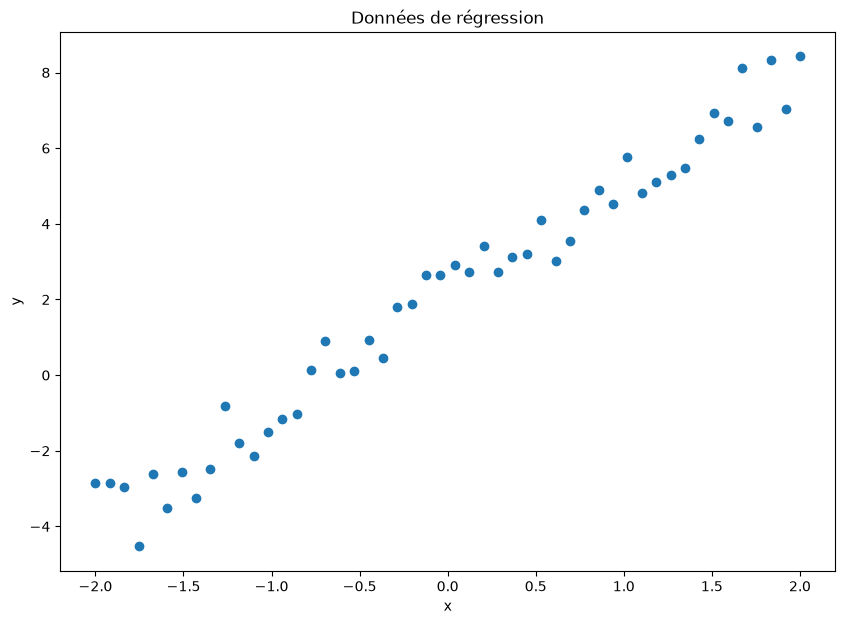

In [88]:
plt.figure(figsize=(10,7))
plt.scatter(x,y)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Données de régression")
plt.show()

**`model = nn.Linear(1, 1)`** crée une couche linéaire élémentaire, autrement dit un unique neurone sans fonction d'activation, qui calcule exactement l'équation d'une droite affine :

$$y = w \cdot x + b$$

In [89]:
model=nn.Linear(1,1)

On utilise la **MSE** comme fonction de perte et l'optimiseur **Adam**. On est bien en mode entraînement : `model.train()`.

In [90]:
loss_function=nn.MSELoss()
optimizer=torch.optim.Adam(model.parameters(),lr=0.05)
epochs=500
losses=[]
for epoch in range(epochs):
  model.train()
  y_pred=model(x)
  loss=loss_function(y_pred,y)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  losses.append(loss.item())
  if epoch % 100==0:
    print(f"Epoch : {epoch}/{epochs} , loss={loss.item():.4f}")

Epoch : 0/500 , loss=13.9100
Epoch : 100/500 , loss=0.3886
Epoch : 200/500 , loss=0.3880
Epoch : 300/500 , loss=0.3880
Epoch : 400/500 , loss=0.3880


Pour connaître le dernier loss, ainsi que le $w$ appris et le $b$ appris. On s'attend à $w \approx 3$ et $b \approx 2$, les valeurs utilisées pour générer les données.

In [91]:
print("Dernier loss :", losses[-1])
print("w appris :", model.weight.item())
print("b appris :", model.bias.item())

Dernier loss : 0.3880296051502228
w appris : 2.9934282302856445
b appris : 2.0573973655700684


# Visualisation de l'évolution du loss

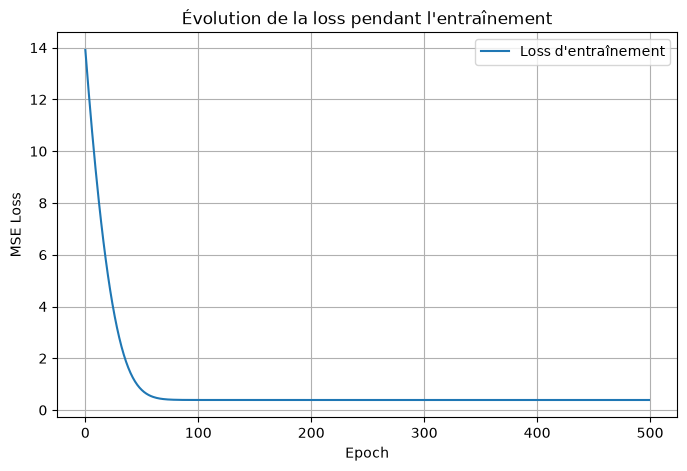

In [92]:
plt.figure(figsize=(8, 5))
plt.plot(losses, label="Loss d'entraînement")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Évolution de la loss pendant l'entraînement")
plt.grid(True)
plt.legend()
plt.show()

# `torch.inference_mode()`

Désactive le moteur Autograd et le suivi interne des tenseurs pour économiser de la mémoire (VRAM) et accélérer les calculs. On est bien en mode évaluation : `model.eval()`.

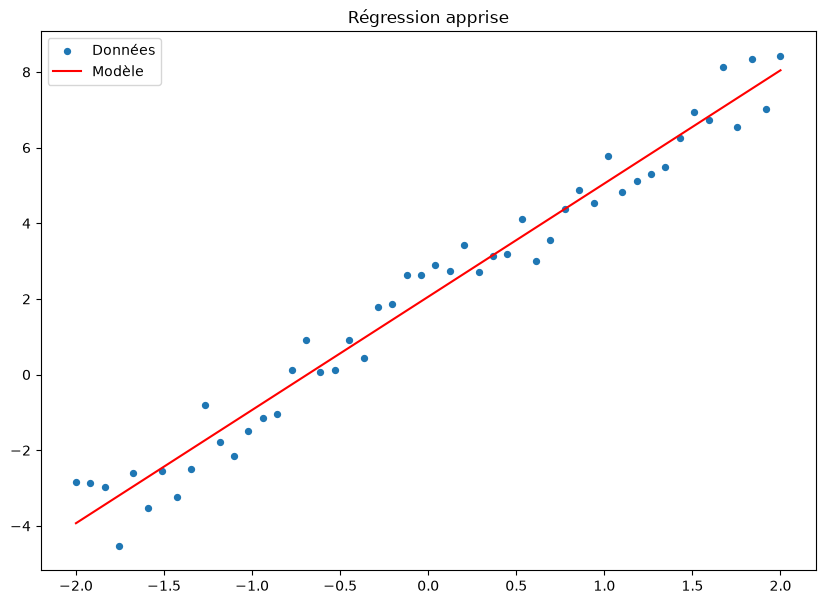

In [93]:
model.eval()
with torch.inference_mode():
  pred_reg=model(x)

plt.figure(figsize=(10,7))
plt.scatter(x.numpy(),y.numpy(),s=18,label="Données")
plt.plot(x.numpy(),pred_reg.numpy(),label="Modèle",c='r')
plt.legend()
plt.title("Régression apprise")
plt.show()

Sur la figure, la droite suit bien la tendance des données : on ne voit ni sur-apprentissage ni sous-apprentissage.

# Calcul du $R^2$

Il se fait avec la classe `R2Score` du module `torcheval.metrics`. Attention à l'ordre des arguments : `update(prédiction, valeur_réelle)`.

In [94]:
from torcheval.metrics import R2Score

In [95]:
r2_score=R2Score()
r2_score.update(pred_reg,y)
score=r2_score.compute()
print(f"R2 score : {score.item():.4f}")

R2 score : 0.9697


# 4. Classification avec PyTorch

On crée d'abord deux classes de points en 2D.

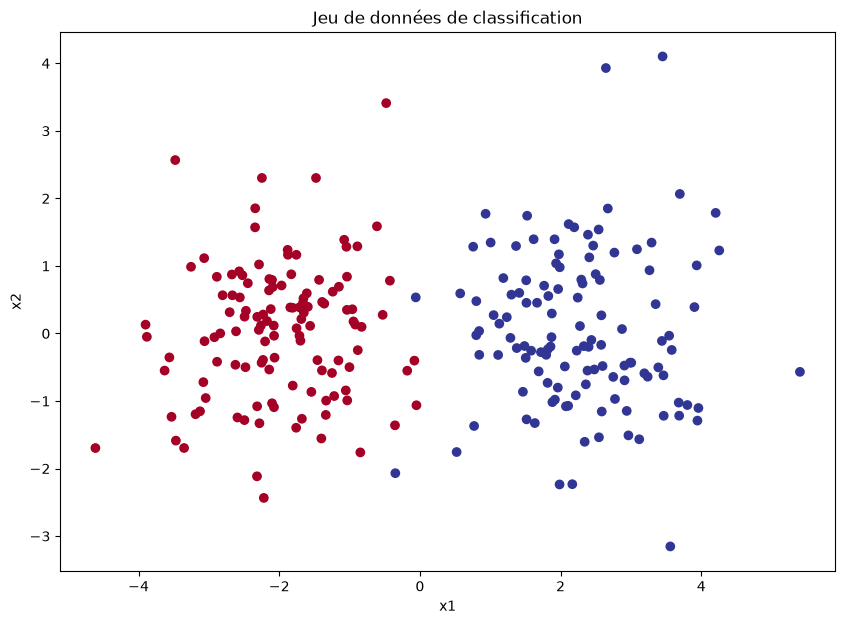

In [96]:
torch.manual_seed(0)
n=120
class0=torch.randn(n,2)+torch.tensor([-2.0,0.0])
class1=torch.randn(n,2)+torch.tensor([2.0,0.0])
X_cls=torch.cat([class0,class1],dim=0)
y_cls=torch.cat([
    torch.zeros(n,dtype=torch.long),
    torch.ones(n,dtype=torch.long)
])
plt.figure(figsize=(10,7))
plt.scatter(X_cls[:,0],X_cls[:,1],c=y_cls,cmap=plt.cm.RdYlBu)
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Jeu de données de classification")
plt.show()

# Classification avec un réseau de neurones artificiels

In [97]:
class Classifier(nn.Module):
  def __init__(self):
    super().__init__()
    self.net=nn.Sequential(
        nn.Linear(2,16),
        nn.ReLU(),
        nn.Linear(16,16),
        nn.ReLU(),
        nn.Linear(16,2)
    )
  def forward(self,x):
    return self.net(x)

Instancier la classe :

In [98]:
model_cls=Classifier()

On définit la fonction de perte et l'optimiseur. Pour la classification on utilise la **Cross Entropy** comme fonction de perte (elle prend directement les *logits*, donc pas besoin de `softmax` à la sortie du réseau).

In [99]:
criterion_cls=nn.CrossEntropyLoss()
optimizer_cls=torch.optim.Adam(model_cls.parameters(),lr=0.01)

In [100]:
epochs_cls=250
losses_cls=[]
for epoch in range(epochs_cls):
  model_cls.train()
  logits=model_cls(X_cls)
  loss=criterion_cls(logits,y_cls)
  optimizer_cls.zero_grad()
  loss.backward()
  optimizer_cls.step()
  losses_cls.append(loss.item())
  if epoch % 100==0:
    print(f"Epoch : {epoch}/{epochs_cls} , loss={loss.item():.4f}")

Epoch : 0/250 , loss=0.6784
Epoch : 100/250 , loss=0.0051
Epoch : 200/250 , loss=0.0012


In [101]:
print("Dernier loss :", losses_cls[-1])

Dernier loss : 0.0006943688495084643


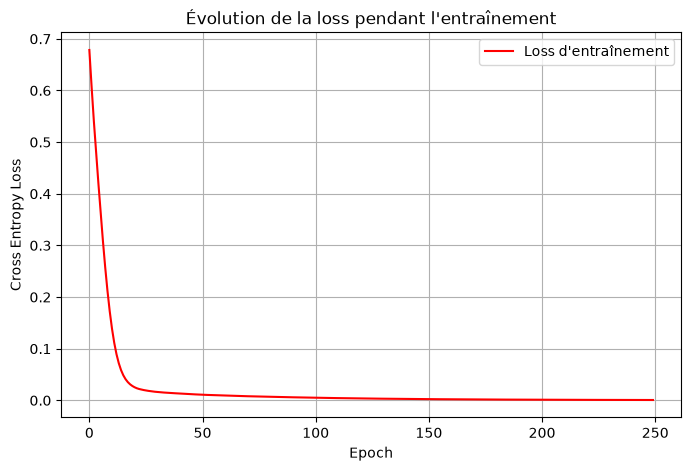

In [102]:
plt.figure(figsize=(8, 5))
plt.plot(losses_cls, label="Loss d'entraînement", c='r')
plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.title("Évolution de la loss pendant l'entraînement")
plt.grid(True)
plt.legend()
plt.show()

# Évaluation du modèle de classification

*Remarque : ici l'évaluation est faite sur les données d'entraînement. Dans un vrai projet, on la ferait sur un jeu de test séparé.*

In [103]:
model_cls.eval()
with torch.inference_mode():
  logits=model_cls(X_cls)
  pred_cls=logits.argmax(dim=1)
  accuracy=(pred_cls==y_cls).float().mean()
  print(f"Accuracy : {accuracy.item()*100:.2f}%")

Accuracy : 100.00%


# Métriques d'évaluation

In [104]:
from torcheval.metrics import BinaryAccuracy, BinaryF1Score, BinaryPrecision, BinaryRecall
from torchmetrics.classification import BinaryConfusionMatrix

In [105]:
accuracy=BinaryAccuracy()
accuracy.update(pred_cls,y_cls)
print(f"Accuracy : {accuracy.compute()*100:.2f}%")

Accuracy : 100.00%


In [106]:
f1_score=BinaryF1Score()
f1_score.update(pred_cls,y_cls)
print(f"F1 Score : {f1_score.compute()*100:.2f}%")

F1 Score : 100.00%


In [107]:
precision=BinaryPrecision()
precision.update(pred_cls,y_cls)
print(f"Precision : {precision.compute()*100:.2f}%")

Precision : 100.00%


In [108]:
recall=BinaryRecall()
recall.update(pred_cls,y_cls)
print(f"Recall : {recall.compute()*100:.2f}%")

Recall : 100.00%


# Matrice de confusion

Avec `torchmetrics`, l'ordre des arguments est `(prédictions, vraies classes)`.

In [109]:
metric=BinaryConfusionMatrix()
confusion_matrix=metric(pred_cls,y_cls)
print(confusion_matrix)

tensor([[120,   0],
        [  0, 120]])


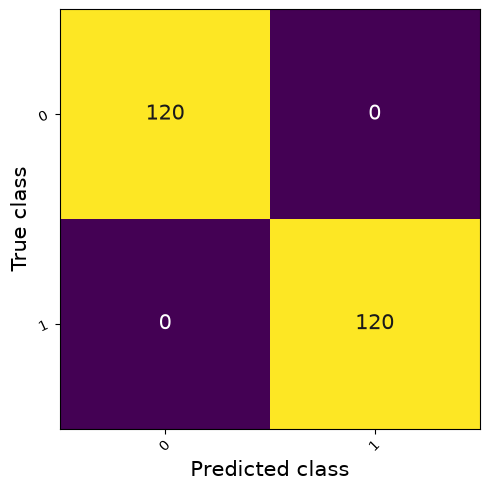

In [110]:
metric.plot()
plt.show()

# Visualisation de la frontière de décision

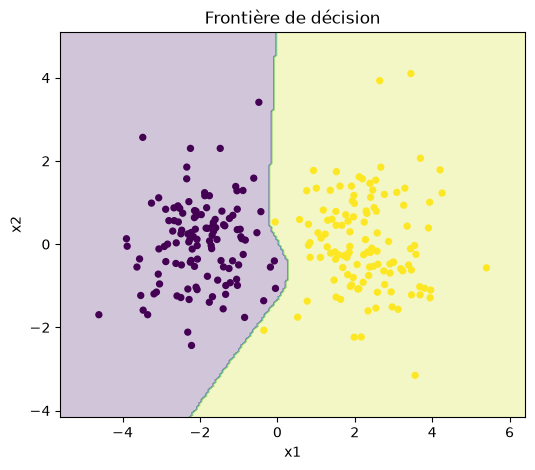

In [111]:
x1_min, x1_max = X_cls[:,0].min().item()-1, X_cls[:,0].max().item()+1
x2_min, x2_max = X_cls[:,1].min().item()-1, X_cls[:,1].max().item()+1
xx1, xx2 = torch.meshgrid(
    torch.linspace(x1_min, x1_max, 200),
    torch.linspace(x2_min, x2_max, 200),
    indexing='ij'
)
grid = torch.stack([xx1.reshape(-1), xx2.reshape(-1)], dim=1)

model_cls.eval()
with torch.inference_mode():
    zz = model_cls(grid).argmax(dim=1).reshape(xx1.shape)
plt.figure(figsize=(6,5))
plt.contourf(xx1.numpy(), xx2.numpy(), zz.numpy(), alpha=0.25)
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Frontière de décision")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

# 5. Création d'un simple MLP

Un **MLP** (*Multi-Layer Perceptron*) est un réseau de couches linéaires séparées par des fonctions d'activation. Ici : 4 entrées → 16 → 8 → 3 sorties.

In [115]:
class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.net=nn.Sequential(
        nn.Linear(4,16),
        nn.ReLU(),
        nn.Linear(16,8),
        nn.ReLU(),
        nn.Linear(8,3)
    )
  def forward(self,x):
    return self.net(x)

Attention : on ne nomme pas l'instance `nn`, sinon elle écraserait le module `torch.nn` importé plus haut.

In [113]:
mlp_model=MLP()
print(mlp_model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


In [116]:
x_test=torch.randn(5,4)      # 5 exemples avec 4 caractéristiques
print(mlp_model(x_test).shape) # attendu : torch.Size([5, 3])

torch.Size([5, 3])


# 6. Dropout : limiter le sur-apprentissage

Le **Dropout** est une couche de régularisation : pendant l'entraînement, `nn.Dropout(p)` met à **0** chaque valeur avec une probabilité `p`. Le réseau ne peut donc pas dépendre toujours des mêmes neurones, ce qui limite le **sur-apprentissage**.

En mode `train()`, avec `p=0.5` :
- chaque valeur est mise à 0 avec une probabilité de 50 % ;
- les valeurs conservées sont multipliées par $\frac{1}{1-p} = \frac{1}{1-0.5} = 2$, pour préserver leur moyenne en espérance.

On obtient donc des **0 et des 2**, répartis aléatoirement.

En mode `eval()`, le Dropout est **désactivé** : il laisse passer les valeurs sans les modifier.

⚠️ `model.eval()` ne désactive pas le calcul des gradients. Pour l'inférence, on l'associe à `torch.inference_mode()`.

In [118]:
class DropoutDemo(nn.Module):
  def __init__(self):
    super().__init__()
    self.dropout=nn.Dropout(p=0.5)

  def forward(self,x):
    return self.dropout(x)


In [120]:

torch.manual_seed(0)
m=DropoutDemo()
x=torch.ones(10)

m.train()
print("train() :", m(x))

m.eval()
with torch.inference_mode():
  print("eval()  :", m(x))

train() : tensor([0., 0., 2., 0., 0., 0., 2., 2., 0., 2.])
eval()  : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


## Dropout dans un réseau

On place `nn.Dropout` **après la fonction d'activation** d'une couche cachée, jamais sur la couche de sortie. Les valeurs de `p` les plus courantes sont entre 0.2 et 0.5.

## 7.MLP avec Dropout

In [123]:
class MLPDropout(nn.Module):
  def __init__(self):
    super().__init__()
    self.net=nn.Sequential(
        nn.Linear(4,16),
        nn.ReLU(),
        nn.Dropout(p=0.3), #  ces couches seront ignorer lors de la phase d'evalution 
        nn.Linear(16,8),
        nn.ReLU(),
        nn.Dropout(p=0.3),
        nn.Linear(8,3)
    )
  def forward(self,x):
    return self.net(x)

mlp_drop=MLPDropout()
print(mlp_drop)

MLPDropout(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=16, out_features=8, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=8, out_features=3, bias=True)
  )
)


In [127]:
x_test=torch.randn(5,4)
print(x_test)

tensor([[-0.9246, -0.5358,  0.4355,  0.9105],
        [ 1.9981, -0.3983, -1.3449,  0.7978],
        [-0.2425, -0.4761, -0.3796, -0.0114],
        [ 1.4446, -1.1639, -1.7151, -0.0545],
        [ 0.8129, -0.9576,  1.2139, -0.5725]])


**train() : le Dropout est actif, deux appels donnent des résultats différents**


In [133]:
mlp_drop.train()
print("train 1 :", mlp_drop(x_test)[0])
print("train 2 :", mlp_drop(x_test)[0])


train 1 : tensor([ 0.2277, -0.0380, -0.0031], grad_fn=<SelectBackward0>)
train 2 : tensor([ 0.1274, -0.1220,  0.0818], grad_fn=<SelectBackward0>)


**eval() : le Dropout est désactivé, deux appels donnent le même résultat**


In [132]:
mlp_drop.eval()
with torch.inference_mode():
  print("eval  1 :", mlp_drop(x_test)[0])
  print("eval  2 :", mlp_drop(x_test)[0])

eval  1 : tensor([ 0.2334, -0.1511,  0.0585])
eval  2 : tensor([ 0.2334, -0.1511,  0.0585])
